# 13 Fashion-MNIST MLP：TT cores-only fine-tuning ablation

`all_parameters`と`tt_cores_only`をTT-rank 16／32／64で比較します。

`tt_cores_only`では`fc1.cores`だけを更新し、`fc1.bias`、`fc2`、`fc3`は固定します。厳密なcontrolled ablationにするため、両更新方式を同じdense checkpointから作った同一のTT置換直後モデル（epoch 0）から独立に開始し、同じepoch 0対応early-stopping loopで再学習します。新規学習は3 ranks × 2 update scopesの6試行です。

データの役割は固定します。

- train 50,000件：fine-tuning
- early-stopping validation 5,000件：checkpoint選択
- rank-selection validation 5,000件：固定済み診断指標の記録
- test 10,000件：予約のみ。このNotebookでは評価しない

Notebook 10／12の結果はhistorical referenceと入力整合確認にだけ使い、13の主比較には混ぜません。TT固有の更新対象設定、epoch 0を含む学習、TT構造の検証はTODOとして自分で実装します。一般的な準備と入力の整合確認は実装済みです。

## 1. 比較したいこと

全parameter更新による回復が、TT cores自身の適応によるものか、後段のdense層などの適応によるものかを切り分けます。

$$
\theta_{\mathrm{all}} = \{G_1,G_2,G_3,b_1,W_2,b_2,W_3,b_3\}
$$

$$
\theta_{\mathrm{TT}} = \{G_1,G_2,G_3\}
$$

比較時に変えるのは更新対象だけです。各rank・各更新方式で初期TT state、seed、mini-batch順、optimizer、学習率、epoch 0を含むearly-stopping規則を揃えます。rank-selection validationは診断専用です。毎epoch記録してもcheckpoint選択、early stopping、学習途中の条件変更には使いません。

In [45]:
# importとプロジェクトルートの解決
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import ast
import copy
import sys
import time
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.compression import (
    TTLinear,
    factorize_named_tt_linear,
    tt_matrix_ranks,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import agreement, count_parameters, logits_rmse
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate, train_one_epoch
from nn_compression.utils import (
    find_project_root,
    get_experiment_dirs,
    make_torch_generator,
    set_seed,
)


In [46]:
# Notebook 10〜12と同じ実験条件を使う。
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
TRAIN_BATCH_SIZE = 64
VALIDATION_BATCH_SIZE = 64
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 5
MIN_DELTA = 1e-4
SAVE_RESULTS = True

set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "30_tt_mps",
    "10_fashion_mnist_mlp",
    "13_tt_cores_only_ablation",
    create=False,
)
baseline_checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
selection_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
    / "selected_tensorizations.csv"
)
notebook10_results_dir = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "10_pretrained_mlp_fc1_tt_finetuning"
)
notebook12_results_dir = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "12_epoch0_checkpoint_selection_and_reproducibility"
)
notebook12_models_dir = (
    project_root / "models" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "12_epoch0_checkpoint_selection_and_reproducibility"
)
selected_metrics_path = notebook12_results_dir / "selected_checkpoint_metrics.csv"
history10_path = notebook10_results_dir / "finetuning_history.csv"
comparison10_path = notebook10_results_dir / "finetuning_comparison.csv"

required_input_paths = [
    baseline_checkpoint_path, selection_path, selected_metrics_path,
    history10_path, comparison10_path,
]
for required_path in required_input_paths:
    if not required_path.is_file():
        raise FileNotFoundError(f"必要な入力がありません: {required_path}")

print("device:", DEVICE)
print("results target:", results_dir)


device: cuda
results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\13_tt_cores_only_ablation


## 2. 入力の整合確認

09のtensorization、10の学習履歴、12のepoch 0対応済み選択結果を接続します。12のcheckpointは参照確認に使えますが、`tt_cores_only`の初期値には使いません。各条件は必ずdense baselineからTT-SVDをやり直し、同じepoch 0を作ります。

In [47]:
df_selected = pd.read_csv(selection_path)
df_selected12 = pd.read_csv(selected_metrics_path)
df_history10 = pd.read_csv(history10_path)
df_comparison10 = pd.read_csv(comparison10_path)

for frame in [df_selected, df_selected12, df_comparison10]:
    for column in ["out_modes", "in_modes", "actual_ranks"]:
        if column in frame.columns:
            frame[column] = frame[column].map(
                lambda value: tuple(ast.literal_eval(value))
                if isinstance(value, str) else tuple(value)
            )

role_order = ["aggressive", "balanced", "conservative"]
expected_ranks = {"aggressive": 16, "balanced": 32, "conservative": 64}
required_selection_columns = {
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks", "model_parameters",
}
required_12_columns = {
    "selection_role", "tensorization", "requested_rank",
    "selection_source", "selected_epoch", "selection_criterion",
    "selection_scope", "model_parameters", "model_compression_ratio",
    "rank_validation_accuracy", "prediction_agreement", "logits_rmse",
}
if missing := required_selection_columns.difference(df_selected.columns):
    raise ValueError(f"09のCSVに必須列がありません: {sorted(missing)}")
if missing := required_12_columns.difference(df_selected12.columns):
    raise ValueError(f"12のCSVに必須列がありません: {sorted(missing)}")

assert set(df_selected["selection_role"]) == set(role_order)
assert set(df_selected12["selection_role"]) == set(role_order)
assert set(df_history10["selection_role"]) == set(role_order)
assert not df_selected["selection_role"].duplicated().any()
assert not df_selected12["selection_role"].duplicated().any()

for role, expected_rank in expected_ranks.items():
    row09 = df_selected.loc[df_selected["selection_role"] == role].iloc[0]
    row12 = df_selected12.loc[df_selected12["selection_role"] == role].iloc[0]
    assert row09["tensorization"] == row12["tensorization"] == "reversed_sites"
    assert int(row09["requested_rank"]) == int(row12["requested_rank"]) == expected_rank
    assert tuple(row09["actual_ranks"]) == tuple(row12["actual_ranks"])
    assert int(row09["model_parameters"]) == int(row12["model_parameters"])
    checkpoint_path = notebook12_models_dir / f"{role}_selected.pt"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"12のselected checkpointがありません: {checkpoint_path}")

assert set(df_selected12["selection_criterion"]) == {"early_stopping_validation_loss"}
assert set(df_selected12["selection_scope"]) == {"post_hoc_epoch0_vs_saved_trained_best"}
assert dict(zip(df_selected12["selection_role"], df_selected12["selection_source"])) == {
    "aggressive": "trained_best",
    "balanced": "trained_best",
    "conservative": "epoch0",
}

display(df_selected12[[
    "selection_role", "requested_rank", "selection_source",
    "selected_epoch", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse",
]])
display(df_selected["selection_role"])

,selection_role,requested_rank,selection_source,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse
0,aggressive,16,trained_best,5,0.8890,0.9314,3.666437
1,balanced,32,trained_best,5,0.8850,0.9298,7.104990
2,conservative,64,epoch0,0,0.8872,0.9922,0.179470


0      aggressive
1        balanced
2    conservative
Name: selection_role, dtype: str

## 3. データ分割とdense baseline

Notebook 10〜12と同じseed・分割・前処理を再利用します。`test_dataset_reserved`は長さだけ確認し、loaderを評価関数へ渡しません。

In [48]:
set_seed(SEED)
full_train_dataset, test_dataset_reserved = get_fashion_mnist_datasets(
    data_dir, download=False,
)
train_dataset, early_stopping_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(full_train_dataset, (50_000, 5_000, 5_000), seed=SEED)
)
loaders = make_fashion_mnist_loaders(
    train_dataset, early_stopping_dataset, test_dataset_reserved,
    train_batch_size=TRAIN_BATCH_SIZE,
    validation_batch_size=VALIDATION_BATCH_SIZE,
    test_batch_size=1000,
    rank_validation_dataset=rank_validation_dataset,
    train_generator=make_torch_generator(SEED),
)
train_loader = loaders["train_loader"]
early_stopping_loader = loaders["validation_loader"]
rank_validation_loader = loaders["validation_loader_rank"]
criterion = torch.nn.CrossEntropyLoss()

baseline_state = torch.load(
    baseline_checkpoint_path, map_location=DEVICE, weights_only=True,
)
baseline_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
baseline_model.load_state_dict(baseline_state)
baseline_model.eval()
baseline_rank_loss, baseline_rank_accuracy = evaluate(
    baseline_model, rank_validation_loader, criterion, DEVICE,
)
baseline_parameters = count_parameters(baseline_model)

assert len(train_dataset) == 50_000
assert len(early_stopping_dataset) == 5_000
assert len(rank_validation_dataset) == 5_000
assert len(test_dataset_reserved) == 10_000
print(f"dense rank-validation: loss={baseline_rank_loss:.6f}, accuracy={baseline_rank_accuracy:.4f}")
print("test set: reserved and not evaluated")


dense rank-validation: loss=0.310588, accuracy=0.8884
test set: reserved and not evaluated


## 4. 過去の`all_parameters`結果を参照する

Notebook 12でepoch 0を含めて選び直した結果はhistorical referenceとして表示します。rank 64はepoch 0、rank 16・32はtrained bestでした。

ただしNotebook 10の学習loopはepoch 0を初期bestとしたpatience軌跡ではありません。Notebook 13の主比較では、`all_parameters`も`tt_cores_only`と同じ新しいloopで再学習します。過去結果を主比較表へ混ぜません。

Notebook 10の履歴にはepochごとのlossとaccuracyはありますが、epochごとのagreementとlogits RMSEはありません。存在しない値を補間・推測しません。

In [49]:
df_historical_all_parameters = df_selected12.copy()
df_historical_all_parameters["update_scope"] = "all_parameters"
df_historical_all_parameters["reference_scope"] = "historical_only_not_main_comparison"

df_historical_history10 = df_history10.copy()
df_historical_history10["update_scope"] = "all_parameters"
df_historical_history10["prediction_agreement"] = float("nan")
df_historical_history10["logits_rmse"] = float("nan")
df_historical_history10["history_note"] = (
    "Historical only; Notebook 10 did not record per-epoch agreement or logits RMSE"
)

display(df_historical_all_parameters[[
    "selection_role", "requested_rank", "reference_scope",
    "selection_source", "selected_epoch", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse", "model_compression_ratio",
]])


,selection_role,requested_rank,reference_scope,selection_source,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_compression_ratio
0,aggressive,16,historical_only_not_main_comparison,trained_best,5,0.8890,0.9314,3.666437,3.493265
1,balanced,32,historical_only_not_main_comparison,trained_best,5,0.8850,0.9298,7.104990,2.612090
2,conservative,64,historical_only_not_main_comparison,epoch0,0,0.8872,0.9922,0.179470,1.316758


## TODO実装契約

TODOを1つ実装するたびに、この契約と照合してから次へ進みます。指定されていない学習・評価・可視化・保存を先取りしません。

### TODO 1：epoch 0モデルと更新対象の準備

- 入力：`df_selected`、`baseline_state`、`SEED`、`LEARNING_RATE`
- 行うこと：rank 16／32／64のTT epoch 0を作り、2つの更新方式の`requires_grad`とoptimizerを設定する
- 行わないこと：loaderの使用、forward評価、学習、early stopping、checkpoint保存
- 出力：`candidate_models[(role, update_scope)]`、`optimizers[(role, update_scope)]`、`initial_parameter_states[(role, update_scope)]`、`trainable_parameter_records`
- 完了条件：6モデルが未学習で存在し、同rankの2条件でepoch 0が完全一致する
- 次への接続：TODO 2は上記3辞書の同じ`(role, update_scope)`キーを使う

### TODO 2：6 trialの学習とcheckpoint選択

- 入力：TODO 1の3辞書、`train_dataset`、`early_stopping_loader`、`rank_validation_loader`、`baseline_model`
- 行うこと：trialごとに同じseedのnew train loaderを作り、epoch 0をinitial bestとして学習する
- 行わないこと：rank-selection指標によるcheckpoint選択や停止、test評価、学習途中の条件変更
- 出力：`history_records`、`selected_records`、`selected_models[(role, update_scope)]`
- 完了条件：6 trialすべてがepoch 0を含む同じearly-stopping規則で選択済みstateへ復元される
- 次への接続：TODO 3は`selected_models`とTODO 1の学習前stateを比較する

### TODO 3：frozen parameterとTT構造の検証

- 入力：`selected_models`、`initial_parameter_states`、`initial_core_shapes`、`initial_actual_ranks`
- 行うこと：named parameterごとの完全一致、変化量、rank、shape、総parameter数を検証する
- 行わないこと：再学習、optimizer操作、評価指標の再計算、条件選択
- 出力：`frozen_verification_records`
- 完了条件：`tt_cores_only`のfrozen parameterがすべて`torch.equal=True`で、TT rankとcore shapeが不変
- 次への接続：TODO 4が検証recordをDataFrame化する

### TODO 4：比較表の作成

- 入力：`selected_records`、`history_records`、`trainable_parameter_records`、`frozen_verification_records`
- 行うこと：4つのDataFrameを所定の列とlong形式で作り、行数・値域・一意性をassertする
- 行わないこと：指標の再評価、historical resultの主比較への混入、可視化、保存
- 出力：`df_update_scope_comparison`、`df_update_scope_history`、`df_trainable_parameters`、`df_frozen_parameter_verification`
- 完了条件：比較表が6行で、`(selection_role, update_scope)`が一意
- 次への接続：TODO 5はこの4表だけを描画元にする

### TODO 5：可視化

- 入力：TODO 4の4つのDataFrame、`baseline_rank_accuracy`
- 行うこと：accuracy、agreement、logits RMSE、trainable parameter数、学習曲線を指定のFigure変数へ描画する
- 行わないこと：モデル評価、条件選択、accuracyとagreementの同一軸表示、historical historyと13の主履歴の混合
- 出力：`fig_accuracy`、`fig_agreement`、`fig_logits_rmse`、`fig_trainable_parameters`、`fig_learning_curves`
- 完了条件：5つのFigureが存在し、rank軸と16／32／64が読める
- 次への接続：TODO 6がFigure変数をそのまま保存する

### TODO 6：13専用成果物の保存

- 入力：TODO 2の`selected_models`、TODO 4の4表、TODO 5の5 Figure
- 行うこと：13専用の`results_dir`と`models_dir`へCSV、PNG、6 checkpointを保存する
- 行わないこと：10／12の上書き・複製、test評価、再学習、結果を見た条件変更
- 出力：4 CSV、5 PNG、6つの`state_dict` checkpoint
- 完了条件：予定した成果物がすべて`is_file()`で確認できる
- 次への接続：13の結果確認後に、学習率診断とlogits drift分解の要否だけを判断する


## TODO 1：2つの更新対象を設定する

### このセルで確認すること

各rank・各更新方式についてdense baselineからTT-SVDを行い、同一のepoch 0を作ります。`all_parameters`では全parameter、`tt_cores_only`では`TTLinear.cores`だけを学習可能にします。

### 実装方針

1. rankごとに新しい`MNISTMLP`へ`baseline_state`を読み込み、`factorize_named_tt_linear`で`fc1`をTTLinearへ置換する。
2. epoch 0のstate dictをcloneし、両更新方式が完全に同じstateから始まることを検証する。
3. `all_parameters`では全parameterを`requires_grad=True`にする。
4. `tt_cores_only`では名前が`fc1.cores.`で始まるparameterだけ`requires_grad=True`にする。
5. optimizerには各条件で`requires_grad=True`のparameterだけを渡す。
6. 更新対象名、各parameterの要素数、合計trainable parameter数、学習前stateを記録する。

### 期待する検証結果

- 両条件のepoch 0 state dictはparameterごとに完全一致する。
- `tt_cores_only`の更新対象は`fc1.cores.0`、`fc1.cores.1`、`fc1.cores.2`だけである。
- optimizerのparameter集合と学習可能parameter集合が一致する。
- actual rank、core shape、総parameter数は09・12と一致する。

既存の`TTLinear`、`factorize_named_tt_linear`、`tt_matrix_ranks`を使い、同じ機能の関数を作り直さないでください。

In [50]:
# TODO 1: rank × update_scopeごとに同じepoch 0モデルを構築し、
# 更新対象を設定する。
#
# 用意するもの:
# - candidate_models: (role, update_scope) -> epoch 0のTTモデル
# - initial_parameter_states: (role, update_scope) -> 学習前named parameterのclone
# - trainable_parameter_records: 更新対象名とnumelの記録
# - optimizers: (role, update_scope) -> trainable parameterだけを渡したAdam
#
# optimizerを作る前にset_seed(SEED)を呼び、各trialを独立に初期化する。
# 同じrankの2条件でepoch 0 stateが完全一致することをassertする。
#
# 【今回整理したこと】
# TODO 1は「比較実験の準備」であり、追加学習は行わない。
# 学習済みbaselineの重みからTTモデルを作り、更新対象とoptimizerを用意する。
# train_one_epoch、early stopping、学習後の診断評価はTODO 2で行う。
#
# 「epoch 0」は、denseモデルの未学習状態ではない。
# 学習済みdenseモデルをTT化した直後、追加学習をまだしていない状態を指す。
#
# 元のbaseline_model自体を更新するのではなく、
# baseline_stateから別のTTモデルを作って比較実験に使う。

update_scopes = ("all_parameters", "tt_cores_only")
candidate_models = {}
initial_parameter_states = {}
trainable_parameter_records = []
optimizers = {}
initial_core_shapes = {}
initial_actual_ranks = {}


# TT coresだけを更新する条件で許可するparameter名。
# この条件では、fc1のbiasや他の層のparameterは更新対象にしない。
expected_core_names = {
    "fc1.cores.0",
    "fc1.cores.1",
    "fc1.cores.2",
}


# role="aggressive"のrank 16だけでなく、選択済みの3 rankすべてを準備する。
# 3 rank × 2更新方式で、合計6 trialになる。
for row in df_selected.sort_values("requested_rank").itertuples(index=False):
    role = str(row.selection_role)
    rank = int(row.requested_rank)

    # rankごとのモデル構築で、初期化時の乱数条件をそろえる。
    # TODO 2で行う「trialごとのtrain loaderのgenerator再作成」とは別の準備。
    set_seed(SEED)

    # 新しいMLPへ学習済みdense checkpointを読み込む。
    # 新しいインスタンスを作るが、ランダムな重みのまま学習するわけではない。
    epoch0_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
    epoch0_model.load_state_dict(baseline_state)

    # 学習済みdenseモデルの対象層をTTLinearへ置き換える。
    # ここではTT化するだけで、train_one_epochによる追加学習はまだ行わない。
    epoch0_model = factorize_named_tt_linear(
        epoch0_model,
        TARGET_LAYER,
        out_modes=tuple(row.out_modes),
        in_modes=tuple(row.in_modes),
        max_rank=rank,
    )

    # 選択時の記録と同じTT構造・parameter数になっているか確認する。
    # requested_rankとactual_ranksは区別して記録・確認する。
    assert isinstance(epoch0_model.fc1, TTLinear)
    actual_ranks = tt_matrix_ranks(list(epoch0_model.fc1.cores))
    core_shapes = tuple(
        tuple(core.shape)
        for core in epoch0_model.fc1.cores
    )
    assert actual_ranks == tuple(row.actual_ranks)
    assert count_parameters(epoch0_model) == int(row.model_parameters)

    # 同じrankの2条件は、同じepoch 0モデルをdeepcopyして作る。
    # 比較したい違いは「更新範囲」なので、初期parameterは同じにする。
    # 2つは別モデルとして保持し、一方の学習結果を他方の出発点にしない。
    models_for_scope = {
        "all_parameters": copy.deepcopy(epoch0_model),
        "tt_cores_only": copy.deepcopy(epoch0_model),
    }

    for update_scope, model in models_for_scope.items():
        # いったん全parameterを固定してから、更新対象を明示的に設定する。
        # ここで設定するのは「後で学習するときに、どこを更新するか」。
        # requires_gradの設定だけでは、まだ重みは更新されない。
        for parameter in model.parameters():
            parameter.requires_grad_(False)

        if update_scope == "all_parameters":
            # TT coresだけでなく、biasや他の層も含めて全parameterを更新する。
            for parameter in model.parameters():
                parameter.requires_grad_(True)
        else:
            # TT coresだけを更新し、それ以外は固定する。
            # "fc1.cores."というprefixで対象を判定し、
            # 下のassertで指定した3 coreだけになっているか確認する。
            for name, parameter in model.named_parameters():
                is_core = name.startswith("fc1.cores.")
                parameter.requires_grad_(is_core)

        # 更新対象の名前とparameterを一緒に取り出す。
        # 名前は確認・記録に、parameter本体はoptimizer作成に使う。
        trainable_named_parameters = [
            (name, parameter)
            for name, parameter in model.named_parameters()
            if parameter.requires_grad
        ]
        trainable_names = {
            name
            for name, _ in trainable_named_parameters
        }
        trainable_parameters = [
            parameter
            for _, parameter in trainable_named_parameters
        ]

        # parameterの「個数」ではなく、更新対象の総要素数を数える。
        trainable_parameter_count = sum(
            parameter.numel()
            for parameter in trainable_parameters
        )

        # 更新対象を設定しただけで終わらず、設定結果を検証する。
        if update_scope == "all_parameters":
            assert trainable_names == {
                name
                for name, _ in model.named_parameters()
            }
            assert trainable_parameter_count == count_parameters(model)
        else:
            assert trainable_names == expected_core_names

        # 更新対象だけを渡し、trialごとに別のAdamを用意する。
        # optimizerを作る段階では学習しない。更新処理はTODO 2で実行する。
        optimizer = torch.optim.Adam(
            trainable_parameters,
            lr=LEARNING_RATE,
        )

        # optimizerが持つparameterと、意図した更新対象が完全に一致するか確認する。
        optimizer_parameter_ids = {
            id(parameter)
            for group in optimizer.param_groups
            for parameter in group["params"]
        }
        assert optimizer_parameter_ids == {
            id(parameter)
            for parameter in trainable_parameters
        }

        # TODOの指定に合わせて、辞書のキーを(role, update_scope)に統一する。
        # 以前のcandidate_models[rank][update_scope]とは取り出し方が異なる。
        # TODO 2では同じkeyでmodel、optimizer、初期状態を取り出す。
        key = (role, update_scope)
        candidate_models[key] = model
        optimizers[key] = optimizer

        # 更新対象だけでなく、全named parameterの学習前の値を保存する。
        # 同rankの初期値一致確認や、学習後のparameter変化の確認に使う。
        # cloneして、学習中に更新されるmodelのparameterとは分けて保持する。
        initial_parameter_states[key] = {
            name: parameter.detach().clone()
            for name, parameter in model.named_parameters()
        }

        # 学習前のTT構造もtrialごとに保存する。
        initial_core_shapes[key] = tuple(
            tuple(core.shape)
            for core in model.fc1.cores
        )
        initial_actual_ranks[key] = tt_matrix_ranks(
            list(model.fc1.cores)
        )

        # 更新対象名と要素数を記録する。
        # 計算しただけで終わらず、条件ごとの情報を後から確認できるように残す。
        for name, parameter in trainable_named_parameters:
            trainable_parameter_records.append({
                "selection_role": role,
                "requested_rank": rank,
                "update_scope": update_scope,
                "parameter_name": name,
                "numel": parameter.numel(),
                "trainable_parameters": trainable_parameter_count,
            })

        assert initial_core_shapes[key] == core_shapes
        assert initial_actual_ranks[key] == actual_ranks
        assert count_parameters(model) == int(row.model_parameters)

    # 同じrankの2条件が、同じ初期parameter・TT構造から始まることを確認する。
    # requires_gradとoptimizerの更新対象は異なるが、parameterの値は同じにする。
    all_key = (role, "all_parameters")
    cores_key = (role, "tt_cores_only")

    assert initial_parameter_states[all_key].keys() == (
        initial_parameter_states[cores_key].keys()
    )
    for name in initial_parameter_states[all_key]:
        assert torch.equal(
            initial_parameter_states[all_key][name],
            initial_parameter_states[cores_key][name],
        ), f"epoch 0が一致しません: {role}, {name}"

    assert initial_core_shapes[all_key] == initial_core_shapes[cores_key]
    assert initial_actual_ranks[all_key] == initial_actual_ranks[cores_key]


# 6 trial分のモデル・optimizer・初期parameterがそろったことを確認する。
assert len(candidate_models) == 6
assert len(optimizers) == 6
assert len(initial_parameter_states) == 6


df_trainable_parameter_setup = pd.DataFrame(trainable_parameter_records)
display(
    df_trainable_parameter_setup.groupby(
        ["selection_role", "requested_rank", "update_scope"],
        as_index=False,
    )["trainable_parameters"].first()
)
print("TODO 1: six untrained epoch-0 models are ready")


# TODO 1はここで終了。以下の学習・評価処理はTODO 2に置く。
#
# TODO 2で使うloaderの役割:
# - train_loader:
#     TTモデルの追加学習で重みを更新する。
# - early_stopping_loader:
#     epoch 0と各epochのlossを確認し、best stateと停止時点を決める。
# - rank_validation_loader:
#     各epochとbest state復元後のaccuracy・agreement・RMSEを診断する。
#     この指標をbest stateの選択やearly stoppingの判断には使わない。
#
# TODO 2ではtrialごとにmake_torch_generator(SEED)を使ってtrain loaderを作り直す。
# 各trialの開始時にpatience_counter = 0を設定する。
# epoch 0もinitial best stateとして扱い、学習後はbest stateへ復元する。
#
# 診断は既存関数を使い、自前の予測収集・集計ループは新しく作らない:
# - evaluate(model, rank_validation_loader, criterion, DEVICE)
# - agreement(baseline_model, model, rank_validation_loader, DEVICE)
# - logits_rmse(baseline_model, model, rank_validation_loader, DEVICE)
#
# test_dataset_reservedは、TODO 2の学習・停止判断・診断には使わない。
#
# TODO 2ですでにcandidate_modelsを学習させた後、epoch 0からやり直したい場合は、
# このTODO 1セルを再実行してモデルとoptimizerを作り直す。

,selection_role,requested_rank,update_scope,trainable_parameters
0,aggressive,16,all_parameters,153386
1,aggressive,16,tt_cores_only,18976
2,balanced,32,all_parameters,205130
3,balanced,32,tt_cores_only,70720
4,conservative,64,all_parameters,406922
5,conservative,64,tt_cores_only,272512


TODO 1: six untrained epoch-0 models are ready


## TODO 2：epoch 0を正式に含めて6 trialを学習する

Notebook 12はepoch 0と保存済みbestの事後比較でした。今回は両更新方式ともepoch 0を最初からbest候補とし、patienceの軌跡にも含めます。

### checkpoint選択

epoch 0のearly-stopping validation lossを初期best lossとします。epoch $t$のlossを$L_t$、現在のbestを$L_{\mathrm{best}}$とすると、更新条件はNotebook 10と同じく

$$
L_{\mathrm{best}} - \delta > L_t
$$

です。ここで$\delta=10^{-4}$です。改善しないepochではpatience counterを1増やします。epoch 0のstateは`copy.deepcopy(model.state_dict())`で保持します。

### 各epochで記録するもの

- train loss／accuracy
- early-stopping validation loss／accuracy
- rank-selection validation accuracy
- denseとのprediction agreement
- dense logitsとのRMSE
- 累積学習時間
- best更新の有無とpatience counter

rank-selection validationの指標は診断・比較用に事前固定して記録するだけです。checkpoint選択、early stopping、学習途中の条件変更、trial打ち切りには一切使用しません。`train_one_epoch`、`evaluate`、`agreement`、`logits_rmse`を再利用してください。

### 期待する結果

rank 16／32／64 × 2更新方式の6 trialについて、epoch 0またはepochs 1以降のbest stateが1つ選ばれ、そのstateへ復元されます。各trialは同じseedと、新しく作り直した同じseedのtrain loaderで独立に実行します。

In [51]:
# TODO 2: rank 16／32／64 × 2更新方式の6試行を実装する。
# 実装前に上の「TODO実装契約」の入力・禁止事項・出力を再確認する。
#
# trialごとにtrain loaderをmake_torch_generator(SEED)で作り直し、
# epoch 0を評価してinitial best stateにする。
# その後、最大MAX_EPOCHSまで次を繰り返す。
# 1. train_one_epoch
# 2. early-stopping validationをevaluate
# 3. rank-selection validationでaccuracy/agreement/RMSEを診断記録
# 4. early-stopping lossだけを使いstrict min_deltaでbest stateとpatienceを更新
# 5. PATIENCE回改善しなければ停止
# 最後にbest stateへ復元し、選択済み指標を再評価する。
# rank-selection指標を途中の判断に使わない。
history_records = []
selected_records = []
selected_models = {}

for row in df_selected.sort_values("requested_rank").itertuples(index=False):
    role = str(row.selection_role)
    rank = int(row.requested_rank)

    for update_scope in update_scopes:
        key = (role, update_scope)
        model = candidate_models[key]
        optimizer = optimizers[key]

        # trialごとに乱数条件をそろえる。
        set_seed(SEED)
        trial_loaders = make_fashion_mnist_loaders(
            train_dataset,
            early_stopping_dataset,
            test_dataset_reserved,
            train_batch_size=TRAIN_BATCH_SIZE,
            validation_batch_size=VALIDATION_BATCH_SIZE,
            test_batch_size=1000,
            rank_validation_dataset=rank_validation_dataset,
            train_generator=make_torch_generator(SEED),
        )

        train_loader = trial_loaders["train_loader"]
        early_stopping_loader = trial_loaders["validation_loader"]
        rank_validation_loader = trial_loaders["validation_loader_rank"]
        # 追加学習前のepoch 0を評価する。
        validation_loss, validation_accuracy = evaluate(
            model,
            early_stopping_loader,
            criterion,
            DEVICE,
        )

        # epoch 0を最初の最良候補にする。
        best_loss = validation_loss
        best_epoch = 0
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0

        # epoch 0の診断。checkpoint選択には使わない。
        rank_validation_loss, rank_validation_accuracy = evaluate(
            model,
            rank_validation_loader,
            criterion,
            DEVICE,
        )

        prediction_agreement = agreement(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )

        logits_error = logits_rmse(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )
        # trial開始時点では、追加学習の累積時間は0秒。
        cumulative_training_seconds = 0.0

        history_records.append({
            "selection_role": role,
            "requested_rank": rank,
            "update_scope": update_scope,
            "epoch": 0,
            "train_loss": float("nan"),
            "train_accuracy": float("nan"),
            "validation_loss":validation_loss,
            "validation_accuracy": validation_accuracy,
            "rank_validation_accuracy":rank_validation_accuracy,
            "prediction_agreement": prediction_agreement,
            "logits_rmse":logits_error,
            "cumulative_training_seconds": cumulative_training_seconds,
            "best_updated": True,
            "patience_counter": patience_counter,
        })

        for epoch in range(1, MAX_EPOCHS + 1):
            training_start = time.perf_counter()

            train_loss, train_accuracy = train_one_epoch(
                model,
                train_loader,
                criterion,
                optimizer,
                DEVICE,
            )

            cumulative_training_seconds += (
                time.perf_counter() - training_start
            )

            validation_loss, validation_accuracy = evaluate(
                model,
                early_stopping_loader,
                criterion,
                DEVICE,
            )
            rank_validation_loss, rank_validation_accuracy =  evaluate(
                model,
                rank_validation_loader,
                criterion,
                DEVICE,
            )
            prediction_agreement = agreement(
                baseline_model,
                model,
                rank_validation_loader,
                DEVICE,
            )

            logits_error = logits_rmse(
                baseline_model,
                model,
                rank_validation_loader,
                DEVICE,
            )
            # 判断に使うのはearly-stopping側のlossだけ。
            if best_loss - validation_loss > MIN_DELTA:
                best_updated = True
                best_loss = validation_loss
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())
                patience_counter = 0
            else:
                best_updated = False
                patience_counter += 1

            # このepochのbest判定後の状態を履歴へ残す。
            history_records.append({
                "selection_role": role,
                "requested_rank": rank,
                "update_scope": update_scope,
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "validation_loss":validation_loss,
                "validation_accuracy": validation_accuracy,
                "rank_validation_accuracy":rank_validation_accuracy,
                "prediction_agreement": prediction_agreement,
                "logits_rmse":logits_error,
                "cumulative_training_seconds": cumulative_training_seconds,
                "best_updated": best_updated,
                "patience_counter": patience_counter,
            })

            if patience_counter >= PATIENCE:
                break

        # epochループの外：選択した最良状態に戻す。
        model.load_state_dict(best_state)

        # 選択済み状態のearly-stopping側の指標を確認する。
        selected_validation_loss, selected_validation_accuracy = evaluate(
            model,
            early_stopping_loader,
            criterion,
            DEVICE,
        )

        # 選択済み状態のrank-selection側の指標を測る。
        selected_rank_loss, selected_rank_accuracy = evaluate(
            model,
            rank_validation_loader,
            criterion,
            DEVICE,
        )

        selected_agreement = agreement(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )

        selected_rmse = logits_rmse(
            baseline_model,
            model,
            rank_validation_loader,
            DEVICE,
        )

        model_parameters = count_parameters(model)
        trainable_parameter_count = sum(
            parameter.numel()
            for parameter in model.parameters()
            if parameter.requires_grad
        )

        selected_records.append({
            "selection_role": role,
            "requested_rank": rank,
            "update_scope": update_scope,
            "selected_epoch": best_epoch,
            "rank_validation_accuracy":selected_rank_accuracy,
            "prediction_agreement": selected_agreement,
            "logits_rmse":selected_rmse,
            "model_parameters": model_parameters,
            "model_compression_ratio": baseline_parameters / model_parameters,
            "trainable_parameters": trainable_parameter_count,
            "cumulative_training_seconds": cumulative_training_seconds,
        })

        selected_models[key] = model

assert len(selected_records) == 6
assert len(selected_models) == 6

## TODO 3：frozen parameterとTT構造を検証する

学習前にcloneしたparameterと、best state復元後のparameterを比較します。

- frozen parameter：`torch.equal`で完全一致すること
- TT cores：少なくとも1要素が変化したかを記録すること
- actual ranks、各core shape、総parameter数：学習前後で不変であること

TT coreが変化しなかった場合、即座に成功とみなしてはいけません。ただしepoch 0が選ばれた場合や有効なoptimizer stepが無い場合には変化しないことがあり得るため、選択epoch・gradient・学習履歴と合わせて判定します。各parameterについて結果を`frozen_parameter_verification`へ保存します。

In [52]:
# TODO 3: named parameterごとに学習前後を比較する。
# このTODOでは再学習や評価指標の再計算を行わない。
#
# 記録例:
# selection_role, requested_rank, parameter_name, is_trainable,
# numel, exact_equal, max_abs_change, selected_epoch
#
# frozen parameterはすべてexact_equal=Trueをassertする。
# TT coresの変化はselected_epochと併記して解釈する。
frozen_verification_records = []

# TODO2の結果から「試行 → 選ばれたepoch」の辞書を一度だけ作る。
selected_epoch_by_key = {
    (record["selection_role"], record["update_scope"]):
        record["selected_epoch"]
    for record in selected_records
}
for row in df_selected.sort_values("requested_rank").itertuples(index=False):
    role = str(row.selection_role)
    rank = int(row.requested_rank)

    for update_scope in update_scopes:
        key = (role, update_scope)

        # TODO2で最良状態に復元したモデルを取り出す。
        model = selected_models[key]

        # TODO1で保存した学習前のパラメータを取り出す。
        initial_parameters = initial_parameter_states[key]

        assert isinstance(model.fc1, TTLinear)

        current_core_shapes = tuple(
            tuple(core.shape)
            for core in model.fc1.cores
        )
        current_actual_ranks = tt_matrix_ranks(
            list(model.fc1.cores)
        )

        # 学習前と同じTT構造であることを確認する。
        assert current_core_shapes == initial_core_shapes[key]
        assert current_actual_ranks == initial_actual_ranks[key]

        # 総パラメータ数も選択時の記録と一致することを確認する。
        assert count_parameters(model) == int(row.model_parameters)

        for name, parameter in model.named_parameters():
            # 同じ名前の学習前Tensorを取り出す。
            initial_parameter = initial_parameters[name]

            # 現在の値を取り出す。
            current_parameter = parameter.detach()

            # 学習前後で形状が同じか確認する。
            assert current_parameter.shape == initial_parameter.shape

            # 値が完全に一致するか。
            exact_equal = torch.equal(
                current_parameter,
                initial_parameter,
            )

            # 各要素の変化量の絶対値のうち、最大のもの。
            max_abs_change = (
                current_parameter - initial_parameter
            ).abs().max().item()

            # 固定したパラメータは、値が変わっていないことを確認する。
            if not parameter.requires_grad:
                assert exact_equal, (
                    f"Frozen parameter changed: {key}, {name}"
                )
            
            # ifの外で、学習対象・固定対象の両方を記録する。
            frozen_verification_records.append({
                "selection_role": role,
                "requested_rank": rank,
                "update_scope": update_scope,
                "parameter_name": name,
                "is_trainable": bool(parameter.requires_grad),
                "numel": parameter.numel(),
                "exact_equal": exact_equal,
                "max_abs_change": max_abs_change,
                "selected_epoch": selected_epoch_by_key[key],
            })
# 全ループの外に追加する。
# 6試行分が記録されているか確認する。

recorded_keys = {
    (record["selection_role"], record["update_scope"])
    for record in frozen_verification_records
}
assert recorded_keys == set(selected_models.keys())
assert len(recorded_keys) == 6

# 各モデルの全named parameterが記録されているか確認する。
expected_record_count = sum(
    len(list(model.named_parameters()))
    for model in selected_models.values()
)
assert len(frozen_verification_records) == expected_record_count

# 固定パラメータの記録がすべて完全一致になっているか確認する。
assert all(
    record["exact_equal"]
    for record in frozen_verification_records
    if not record["is_trainable"]
)

## TODO 4：比較用DataFrameを作る

以下の4表を作ります。

- `df_update_scope_comparison`：13で再学習したrank × update scopeの選択済み結果
- `df_update_scope_history`：13の6 trialのepoch履歴
- `df_trainable_parameters`：学習可能parameterの名前と要素数
- `df_frozen_parameter_verification`：固定parameterが変化していないことの検証

比較表はlong形式とし、accuracy、agreement、logits RMSE、圧縮率、総parameter数、trainable parameter数、選択epoch、学習時間を含めます。Notebook 10／12のhistorical referenceは別表のまま保持し、主比較DataFrameへ結合しません。

In [53]:
# TODO 4: 13で再学習した6 trialをlong形式へ整理する。
# recordから表を作るだけとし、モデルの再評価や可視化は行わない。
comparison_columns = [
    "selection_role", "requested_rank", "update_scope",
    "selected_epoch", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse",
    "model_parameters", "model_compression_ratio",
    "trainable_parameters", "cumulative_training_seconds",
]
history_columns = [
    "selection_role", "requested_rank", "update_scope", "epoch",
    "train_loss", "train_accuracy", "validation_loss",
    "validation_accuracy", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse",
    "cumulative_training_seconds", "best_updated",
    "patience_counter",
]
trainable_columns = [
    "selection_role", "requested_rank", "update_scope",
    "parameter_name", "numel",
]
frozen_columns = [
    "selection_role", "requested_rank", "update_scope",
    "parameter_name", "is_trainable", "numel",
    "exact_equal", "max_abs_change", "selected_epoch",
]

role_order = ["aggressive", "balanced", "conservative"]
scope_order = ["all_parameters", "tt_cores_only"]

df_update_scope_comparison = (
    pd.DataFrame(selected_records)[comparison_columns]
    .assign(
        selection_role=lambda df: pd.Categorical(
            df["selection_role"], categories=role_order, ordered=True
        ),
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        ),
    )
    .sort_values(["requested_rank", "update_scope"])
    .reset_index(drop=True)
)

df_update_scope_history = (
    pd.DataFrame(history_records)[history_columns]
    .assign(
        selection_role=lambda df: pd.Categorical(
            df["selection_role"], categories=role_order, ordered=True
        ),
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        ),
    )
    .sort_values(["requested_rank", "update_scope", "epoch"])
    .reset_index(drop=True)
)

df_trainable_parameters = (
    pd.DataFrame(trainable_parameter_records)[trainable_columns]
    .assign(
        selection_role=lambda df: pd.Categorical(
            df["selection_role"], categories=role_order, ordered=True
        ),
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        ),
    )
    .sort_values(["requested_rank", "update_scope", "parameter_name"])
    .reset_index(drop=True)
)

df_frozen_parameter_verification = (
    pd.DataFrame(frozen_verification_records)[frozen_columns]
    .assign(
        selection_role=lambda df: pd.Categorical(
            df["selection_role"], categories=role_order, ordered=True
        ),
        update_scope=lambda df: pd.Categorical(
            df["update_scope"], categories=scope_order, ordered=True
        ),
    )
    .sort_values(["requested_rank", "update_scope", "parameter_name"])
    .reset_index(drop=True)
)

# --- 構造・値域の検証 ---
assert len(df_update_scope_comparison) == 6
assert (
    df_update_scope_comparison[["selection_role", "update_scope"]]
    .duplicated()
    .sum()
    == 0
)
assert set(df_update_scope_comparison["requested_rank"].astype(int)) == {16, 32, 64}
assert set(df_update_scope_comparison["update_scope"]) == set(scope_order)

assert df_update_scope_history["update_scope"].nunique() == 2
assert df_update_scope_history["requested_rank"].nunique() == 3
assert (
    df_update_scope_history.groupby(
        ["selection_role", "update_scope"], observed=True
    )["epoch"]
    .min()
    == 0
).all()

assert df_update_scope_comparison["rank_validation_accuracy"].between(0.0, 1.0).all()
assert df_update_scope_comparison["prediction_agreement"].between(0.0, 1.0).all()
assert (df_update_scope_comparison["logits_rmse"] >= 0.0).all()
assert (df_update_scope_comparison["model_parameters"] > 0).all()
assert (df_update_scope_comparison["trainable_parameters"] > 0).all()

# frozen は非学習パラメータがすべて exact_equal
assert (
    df_frozen_parameter_verification.loc[
        ~df_frozen_parameter_verification["is_trainable"],
        "exact_equal",
    ]
    .all()
)

display(df_update_scope_comparison.round(6))
display(df_update_scope_history.head(12))
display(
    df_trainable_parameters.groupby(
        ["selection_role", "requested_rank", "update_scope"],
        observed=True,
        as_index=False,
    )["numel"].sum()
)
display(df_frozen_parameter_verification.head(12))


,selection_role,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,trainable_parameters,cumulative_training_seconds
0,aggressive,16,all_parameters,5,0.8890,0.9314,3.666437,153386,3.493265,153386,37.295998
1,aggressive,16,tt_cores_only,12,0.8904,0.9186,4.309767,153386,3.493265,18976,60.872936
2,balanced,32,all_parameters,5,0.8850,0.9298,7.104990,205130,2.612090,205130,55.628776
3,balanced,32,tt_cores_only,5,0.8926,0.9362,4.571566,205130,2.612090,70720,55.030346
4,conservative,64,all_parameters,0,0.8872,0.9922,0.179470,406922,1.316758,406922,55.455132
5,conservative,64,tt_cores_only,0,0.8872,0.9922,0.179470,406922,1.316758,272512,55.634748


,selection_role,requested_rank,update_scope,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,rank_validation_accuracy,prediction_agreement,logits_rmse,cumulative_training_seconds,best_updated,patience_counter
0,aggressive,16,all_parameters,0,NaN,NaN,1.308600,0.5110,0.5116,0.5276,7.933703,0.000000,True,0
1,aggressive,16,all_parameters,1,0.394260,0.85120,0.383005,0.8512,0.8502,0.8890,3.280542,3.764973,True,0
2,aggressive,16,all_parameters,2,0.330835,0.87552,0.323231,0.8810,0.8796,0.9146,3.077799,7.446643,True,0
3,aggressive,16,all_parameters,3,0.305045,0.88414,0.332790,0.8780,0.8834,0.9118,2.858770,11.268172,False,1
4,aggressive,16,all_parameters,4,0.284750,0.89220,0.323432,0.8808,0.8796,0.9172,3.183747,15.141393,False,2
5,aggressive,16,all_parameters,5,0.267224,0.89898,0.305269,0.8868,0.8890,0.9314,3.666437,18.924854,True,0
6,aggressive,16,all_parameters,6,0.255276,0.90192,0.310693,0.8854,0.8826,0.9122,3.929824,22.598979,False,1
7,aggressive,16,all_parameters,7,0.242618,0.90790,0.310190,0.8854,0.8860,0.9264,5.215786,26.304017,False,2
8,aggressive,16,all_parameters,8,0.232845,0.91148,0.310775,0.8880,0.8870,0.9176,6.288430,29.954288,False,3
9,aggressive,16,all_parameters,9,0.217116,0.91732,0.328009,0.8880,0.8912,0.9228,7.168516,33.638255,False,4


,selection_role,requested_rank,update_scope,numel
0,aggressive,16,all_parameters,153386
1,aggressive,16,tt_cores_only,18976
2,balanced,32,all_parameters,205130
3,balanced,32,tt_cores_only,70720
4,conservative,64,all_parameters,406922
5,conservative,64,tt_cores_only,272512


,selection_role,requested_rank,update_scope,parameter_name,is_trainable,numel,exact_equal,max_abs_change,selected_epoch
0,aggressive,16,all_parameters,fc1.bias,True,512,False,0.299913,5
1,aggressive,16,all_parameters,fc1.cores.0,True,1024,False,0.120598,5
2,aggressive,16,all_parameters,fc1.cores.1,True,16384,False,0.366009,5
3,aggressive,16,all_parameters,fc1.cores.2,True,1568,False,0.520414,5
4,aggressive,16,all_parameters,fc2.bias,True,256,False,0.138663,5
5,aggressive,16,all_parameters,fc2.weight,True,131072,False,0.507703,5
6,aggressive,16,all_parameters,fc3.bias,True,10,False,0.084119,5
7,aggressive,16,all_parameters,fc3.weight,True,2560,False,0.588871,5
8,aggressive,16,tt_cores_only,fc1.bias,False,512,True,0.000000,12
9,aggressive,16,tt_cores_only,fc1.cores.0,True,1024,False,0.262903,12


## TODO 5：可視化する

matplotlibで次を作ります。

1. rank対validation accuracy：dense baselineを黒い破線で表示
2. rank対prediction agreement：agreementだけを表示
3. rank対logits RMSE
4. rank対trainable parameter数
5. update scope別のlearning curves

accuracyとagreementは比較対象が異なるため、同じ軸へ重ねません。rank軸は底2の対数軸とし、16／32／64を明示します。agreement／RMSEが欠損しているのはNotebook 10のhistorical historyだけです。13で新規収集する6 trialの履歴とは混ぜて描画しないでください。

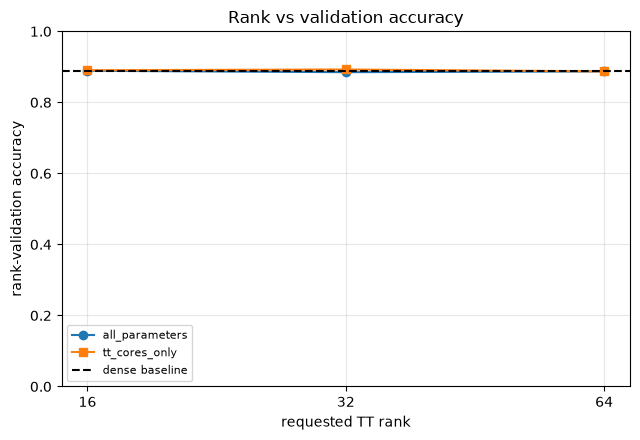

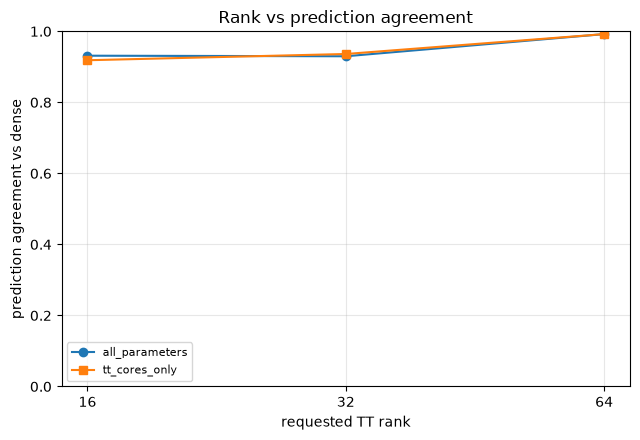

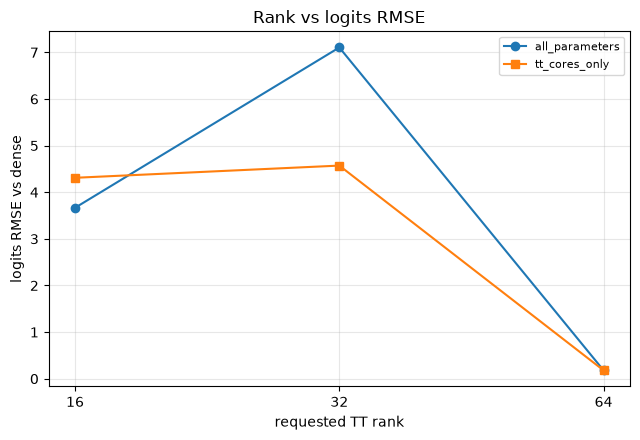

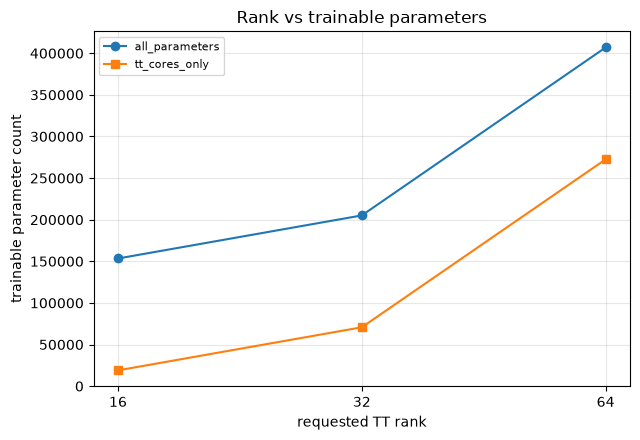

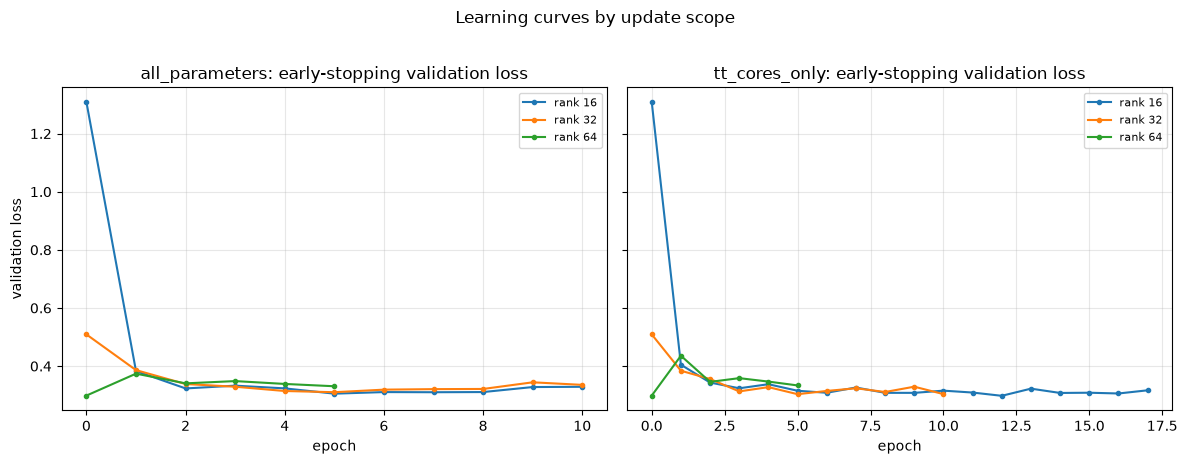

In [54]:
# TODO 5: 比較図と学習曲線を作る。
# TODO 4のDataFrameだけを入力とし、条件選択や再評価は行わない。
# dense baseline線はaccuracy図だけに入れる。
# 作成したFigureを次の変数へ格納する。

ranks = [16, 32, 64]
scope_styles = {
    "all_parameters": {"marker": "o", "label": "all_parameters"},
    "tt_cores_only": {"marker": "s", "label": "tt_cores_only"},
}


def _plot_rank_metric(ax, y_col, ylabel, title, ylim=None, baseline=None):
    for scope, style in scope_styles.items():
        frame = (
            df_update_scope_comparison
            .loc[df_update_scope_comparison["update_scope"] == scope]
            .sort_values("requested_rank")
        )
        ax.plot(
            frame["requested_rank"],
            frame[y_col],
            marker=style["marker"],
            label=style["label"],
        )
    if baseline is not None:
        ax.axhline(
            baseline,
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="dense baseline",
        )
    ax.set_xscale("log", base=2)
    ax.set_xticks(ranks)
    ax.set_xticklabels([str(rank) for rank in ranks])
    ax.set_xlabel("requested TT rank")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)


fig_accuracy, ax_acc = plt.subplots(figsize=(6.5, 4.5))
_plot_rank_metric(
    ax_acc,
    "rank_validation_accuracy",
    "rank-validation accuracy",
    "Rank vs validation accuracy",
    ylim=(0.0, 1.0),
    baseline=baseline_rank_accuracy,
)
fig_accuracy.tight_layout()
plt.show()

fig_agreement, ax_agr = plt.subplots(figsize=(6.5, 4.5))
_plot_rank_metric(
    ax_agr,
    "prediction_agreement",
    "prediction agreement vs dense",
    "Rank vs prediction agreement",
    ylim=(0.0, 1.0),
)
fig_agreement.tight_layout()
plt.show()

fig_logits_rmse, ax_rmse = plt.subplots(figsize=(6.5, 4.5))
_plot_rank_metric(
    ax_rmse,
    "logits_rmse",
    "logits RMSE vs dense",
    "Rank vs logits RMSE",
)
fig_logits_rmse.tight_layout()
plt.show()

fig_trainable_parameters, ax_tp = plt.subplots(figsize=(6.5, 4.5))
_plot_rank_metric(
    ax_tp,
    "trainable_parameters",
    "trainable parameter count",
    "Rank vs trainable parameters",
)
fig_trainable_parameters.tight_layout()
plt.show()

# update scope別の learning curves（early-stopping validation loss）
fig_learning_curves, axes_lc = plt.subplots(
    1, 2, figsize=(12, 4.5), sharey=True
)
for ax, scope in zip(axes_lc, scope_styles):
    for rank in ranks:
        history = (
            df_update_scope_history
            .loc[
                (df_update_scope_history["update_scope"] == scope)
                & (df_update_scope_history["requested_rank"] == rank)
            ]
            .sort_values("epoch")
        )
        ax.plot(
            history["epoch"],
            history["validation_loss"],
            marker="o",
            markersize=3,
            label=f"rank {rank}",
        )
    ax.set_xlabel("epoch")
    ax.set_title(f"{scope}: early-stopping validation loss")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes_lc[0].set_ylabel("validation loss")
fig_learning_curves.suptitle(
    "Learning curves by update scope",
    y=1.02,
)
fig_learning_curves.tight_layout()
plt.show()

assert fig_accuracy is not None
assert fig_agreement is not None
assert fig_logits_rmse is not None
assert fig_trainable_parameters is not None
assert fig_learning_curves is not None


## TODO 6：結果を保存する

13専用ディレクトリへ次を保存します。

- `update_scope_comparison.csv`
- `update_scope_history.csv`
- `trainable_parameters.csv`
- `frozen_parameter_verification.csv`
- 各比較図
- rank × update scope別の6つの選択checkpoint

Notebook 10／12のhistorical checkpointは参照元に残っているため、13へ複製しません。test結果も保存しません。

In [55]:
# TODO 6: SAVE_RESULTS=Trueの場合だけCSV、Figure、
# 選択checkpointを保存し、再学習・test評価・既存成果物の上書きは行わない。
# 13で新しく学習した6 trialの選択checkpointを保存する。
# results_dirとmodels_dirは保存直前にmkdirする。
# Notebook 10／12のhistorical checkpointはコピーしない。

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    def prepare_csv_frame(frame):
        """in-memoryのDataFrameは壊さず、CSV用copyだけを整える。"""
        out = frame.copy()
        for column in out.columns:
            if str(out[column].dtype) == "category":
                out[column] = out[column].astype(str)
            elif out[column].map(lambda value: isinstance(value, tuple)).any():
                out[column] = out[column].map(str)
        return out

    path_comparison = results_dir / "update_scope_comparison.csv"
    path_history = results_dir / "update_scope_history.csv"
    path_trainable = results_dir / "trainable_parameters.csv"
    path_frozen = results_dir / "frozen_parameter_verification.csv"

    path_fig_accuracy = results_dir / "update_scope_accuracy.png"
    path_fig_agreement = results_dir / "update_scope_agreement.png"
    path_fig_rmse = results_dir / "update_scope_logits_rmse.png"
    path_fig_trainable = results_dir / "update_scope_trainable_parameters.png"
    path_fig_curves = results_dir / "update_scope_learning_curves.png"

    prepare_csv_frame(df_update_scope_comparison).to_csv(
        path_comparison, index=False
    )
    prepare_csv_frame(df_update_scope_history).to_csv(
        path_history, index=False
    )
    prepare_csv_frame(df_trainable_parameters).to_csv(
        path_trainable, index=False
    )
    prepare_csv_frame(df_frozen_parameter_verification).to_csv(
        path_frozen, index=False
    )

    fig_accuracy.savefig(path_fig_accuracy, dpi=150, bbox_inches="tight")
    fig_agreement.savefig(path_fig_agreement, dpi=150, bbox_inches="tight")
    fig_logits_rmse.savefig(path_fig_rmse, dpi=150, bbox_inches="tight")
    fig_trainable_parameters.savefig(
        path_fig_trainable, dpi=150, bbox_inches="tight"
    )
    fig_learning_curves.savefig(path_fig_curves, dpi=150, bbox_inches="tight")

    checkpoint_paths = []
    for (role, update_scope), model in selected_models.items():
        checkpoint_path = (
            models_dir / f"{role}_{update_scope}_selected.pt"
        )
        torch.save(model.state_dict(), checkpoint_path)
        checkpoint_paths.append(checkpoint_path)
        print("saved checkpoint:", checkpoint_path.name)

    saved_paths = [
        path_comparison,
        path_history,
        path_trainable,
        path_frozen,
        path_fig_accuracy,
        path_fig_agreement,
        path_fig_rmse,
        path_fig_trainable,
        path_fig_curves,
        *checkpoint_paths,
    ]
    for path_item in saved_paths:
        assert path_item.is_file(), path_item

    assert len(checkpoint_paths) == 6
    print("saved tables/figures to:", results_dir)
    print("saved checkpoints to:", models_dir)
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")


saved checkpoint: aggressive_all_parameters_selected.pt
saved checkpoint: aggressive_tt_cores_only_selected.pt
saved checkpoint: balanced_all_parameters_selected.pt
saved checkpoint: balanced_tt_cores_only_selected.pt
saved checkpoint: conservative_all_parameters_selected.pt
saved checkpoint: conservative_tt_cores_only_selected.pt
saved tables/figures to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\13_tt_cores_only_ablation
saved checkpoints to: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\13_tt_cores_only_ablation


## 5. 実装後のチェックリスト

- [x] 新規学習はrank 16／32／64 × `all_parameters`／`tt_cores_only`の6 trialである
- [x] 同じrankの2条件は完全に同じepoch 0 stateから始まる
- [x] 各trialは同じdense checkpoint、seed、新規train loaderから独立に開始する
- [x] `tt_cores_only`の更新対象は`fc1.cores`だけである
- [x] optimizerには各条件の学習可能parameterだけが渡されている
- [x] 両条件でepoch 0がbest候補とpatience軌跡へ正式に含まれている
- [x] checkpoint選択はearly-stopping validation lossだけを使う
- [x] rank-selection validationは選択・停止・途中の条件変更に使っていない
- [x] tt-cores-onlyのfrozen parameterは学習前後で完全一致する
- [x] actual rank、core shape、総parameter数は不変である
- [x] Notebook 10／12のhistorical referenceを主比較へ混ぜていない
- [x] accuracyとagreementを別図にしている
- [x] test setを評価していない

13では最終rankを決定しません。結果を見て、学習率診断とlogits drift分解の要否を判断します。更新方式と学習率を決めた後にrank 12を評価します。

In [57]:
# 入力と実験境界に関する、TODO開始前でも確認できる事項。
assert expected_ranks == {"aggressive": 16, "balanced": 32, "conservative": 64}
assert set(df_selected["tensorization"]) == {"reversed_sites"}
assert set(df_selected12["selection_criterion"]) == {"early_stopping_validation_loss"}
assert len(test_dataset_reserved) == 10_000
assert isinstance(baseline_model.fc1, torch.nn.Linear)

# --- TODO 1〜6 実装後のチェックリスト ---

# 新規学習は rank 16/32/64 × all_parameters/tt_cores_only の6 trial
assert len(selected_records) == 6
assert len(selected_models) == 6
assert set(df_update_scope_comparison["requested_rank"].astype(int)) == {16, 32, 64}
assert set(df_update_scope_comparison["update_scope"].astype(str)) == {
    "all_parameters",
    "tt_cores_only",
}
assert (
    df_update_scope_comparison[["selection_role", "update_scope"]]
    .duplicated()
    .sum()
    == 0
)

# 同じrankの2条件は完全に同じepoch 0 stateから始まる
for role in expected_ranks:
    all_key = (role, "all_parameters")
    cores_key = (role, "tt_cores_only")
    assert initial_parameter_states[all_key].keys() == (
        initial_parameter_states[cores_key].keys()
    )
    for name in initial_parameter_states[all_key]:
        assert torch.equal(
            initial_parameter_states[all_key][name],
            initial_parameter_states[cores_key][name],
        ), f"epoch 0 mismatch: {role}, {name}"

# tt_cores_only の更新対象は fc1.cores だけ
for role in expected_ranks:
    cores_key = (role, "tt_cores_only")
    trainable_names = {
        name
        for name, parameter in candidate_models[cores_key].named_parameters()
        if parameter.requires_grad
    }
    assert trainable_names == {
        "fc1.cores.0",
        "fc1.cores.1",
        "fc1.cores.2",
    }, trainable_names

# optimizer には各条件の学習可能parameterだけが渡されている
for key, optimizer in optimizers.items():
    model = candidate_models[key]
    expected_ids = {
        id(parameter)
        for parameter in model.parameters()
        if parameter.requires_grad
    }
    actual_ids = {
        id(parameter)
        for group in optimizer.param_groups
        for parameter in group["params"]
    }
    assert actual_ids == expected_ids, key

# 両条件で epoch 0 が history に正式に含まれている
history_epoch0 = (
    df_update_scope_history
    .groupby(["selection_role", "update_scope"], observed=True)["epoch"]
    .min()
)
assert (history_epoch0 == 0).all()

# frozen parameter は学習前後で完全一致
assert (
    df_frozen_parameter_verification.loc[
        ~df_frozen_parameter_verification["is_trainable"],
        "exact_equal",
    ]
    .all()
)

# actual rank / core shape / 総parameter数は不変（TODO 3で検証済みキーが残っている）
assert len(initial_core_shapes) == 6
assert len(initial_actual_ranks) == 6
for key, model in selected_models.items():
    assert isinstance(model.fc1, TTLinear)
    assert tuple(tuple(core.shape) for core in model.fc1.cores) == (
        initial_core_shapes[key]
    )
    assert tt_matrix_ranks(list(model.fc1.cores)) == initial_actual_ranks[key]

# Notebook 10/12 の historical reference は主比較へ混ざっていない
assert "source" not in df_update_scope_comparison.columns
assert "historical" not in df_update_scope_comparison.columns
assert len(df_update_scope_comparison) == 6

# accuracy と agreement は別 Figure
assert fig_accuracy is not fig_agreement
assert fig_accuracy is not None
assert fig_agreement is not None
assert fig_logits_rmse is not None
assert fig_trainable_parameters is not None
assert fig_learning_curves is not None

# test set は予約のみ（長さ確認まで。評価用の記録は無い）
assert len(test_dataset_reserved) == 10_000
assert "test_accuracy" not in df_update_scope_comparison.columns
assert "test_loss" not in df_update_scope_comparison.columns

# 成果物が保存されている（SAVE_RESULTS=True のとき）
if SAVE_RESULTS:
    expected_files = [
        results_dir / "update_scope_comparison.csv",
        results_dir / "update_scope_history.csv",
        results_dir / "trainable_parameters.csv",
        results_dir / "frozen_parameter_verification.csv",
        results_dir / "update_scope_accuracy.png",
        results_dir / "update_scope_agreement.png",
        results_dir / "update_scope_logits_rmse.png",
        results_dir / "update_scope_trainable_parameters.png",
        results_dir / "update_scope_learning_curves.png",
    ]
    for role in expected_ranks:
        for update_scope in ("all_parameters", "tt_cores_only"):
            expected_files.append(
                models_dir / f"{role}_{update_scope}_selected.pt"
            )
    for path_item in expected_files:
        assert path_item.is_file(), path_item

print("verification checklist: OK")


verification checklist: OK


## 6. 次へ渡す判断

このNotebookの結果から、まず`all_parameters`と`tt_cores_only`のどちらを今後のrank比較に使うかを決めます。rank 64でepoch 0が再び選ばれる、またはlogits RMSEの増大が残る場合に限り、学習率診断やlogits drift分解を追加します。

更新方式と学習率をvalidationだけで決めた後、rank 12を同条件で追加評価します。test setと最終rank決定はまだ先です。